# Turbulence Super-Resolution — Postprocessing & Evaluation

## Setup and Imports

In [2]:

import sys
from pathlib import Path

def find_project_root(start: Path, target='models', max_up: int = 8) -> Path:
    root = start.resolve()
    for _ in range(max_up):
        if (root / target).exists():
            return root
        if root.parent == root:
            break
        root = root.parent
    raise FileNotFoundError(f"Could not find '{target}' above {start}")

ROOT = find_project_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import csv
import warnings

import h5py
import yaml
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm

from utils.sr_datasets import (
    TemporalStackDataset,
    MultiFieldDataset,
    create_snapshot_splits,
    compute_global_stats,
    compute_multifield_stats,
)
from utils.metrics import psnr, ssim
from utils.physics import (
    gradient_magnitude_2d,
    laplacian_2d,
    advection_u_dot_grad_omega,
    energy_spectrum_2d,
    pdf_from_field,
)
from models.factory import build_model_from_config

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['figure.facecolor'] = 'white'
np.random.seed(42)
torch.manual_seed(42)
warnings.filterwarnings('ignore')

print(f"Project root: {ROOT}")
print(f"GPU available: {torch.cuda.is_available()}")


Project root: /workspaces/jhtdb-ml
GPU available: True


## Configuration, Workspace, and Output Paths

In [29]:

CONFIG_PATH = ROOT / 'configs/sr_unet_meteo_128.yaml'  # ← update as needed
with open(CONFIG_PATH) as fp:
    config = yaml.safe_load(fp)

print('Configuration loaded from:', CONFIG_PATH)
print(json.dumps({
    'experiment': config['experiment']['name'],
    'model': config['model']['architecture'],
    'component': config['data']['component'],
    'scale_factor': config['model']['scale_factor'],
    'physics_enabled': config['loss']['components'].get('physics', {}).get('enabled', False),
}, indent=2))

ckpt_cfg = config['training'].get('checkpoints', {})
BEST_CKPT_NAME = ckpt_cfg.get('best', 'best_model.pth')
LAST_CKPT_NAME = ckpt_cfg.get('last', 'last_model.pth')


Configuration loaded from: /workspaces/jhtdb-ml/configs/sr_unet_meteo_128.yaml
{
  "experiment": "sr_unet_meteo_isotropic",
  "model": "unet_meteo",
  "component": "omega_z",
  "scale_factor": 4,
  "physics_enabled": true
}


## Select Training Run

In [30]:
RUN_DIR = ROOT / 'work/SR/sr_unet_meteo_isotropic_128_withPhysics'  # ← set to the run produced during training
RUN_DIR = RUN_DIR.resolve()
if not RUN_DIR.exists():
    raise FileNotFoundError(f"RUN_DIR does not exist: {RUN_DIR}. Update RUN_DIR to an existing training run directory.")

USE_BEST_CHECKPOINT = False  # ← set True to evaluate the best-val model instead of last-epoch
ckpt_name = BEST_CKPT_NAME if USE_BEST_CHECKPOINT else LAST_CKPT_NAME

print('Using existing run directory:', RUN_DIR)
print(f"  Loading checkpoint: {ckpt_name}")

FIGURES_DIR = RUN_DIR / 'plots'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_EVAL_DIR = FIGURES_DIR / 'evaluation'
FIGURES_EVAL_DIR.mkdir(parents=True, exist_ok=True)

METRICS_DIR = RUN_DIR / 'metrics'
METRICS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_PATH = METRICS_DIR / 'evaluation_metrics.json'
PER_SNAPSHOT_PATH = METRICS_DIR / 'per_snapshot_metrics.csv'

CHECKPOINT_PATH = RUN_DIR / 'checkpoints' / ckpt_name
print('Checkpoint path:', CHECKPOINT_PATH)

evaluation_metrics_summary = {}

Using existing run directory: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics
  Loading checkpoint: last_model.pth
Checkpoint path: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics/checkpoints/last_model.pth


## Load DNS Data and Build Test Dataset

In [5]:

# Load raw DNS data (all fields needed for physics metrics)
h5_path = (ROOT / config['data']['h5_path']).resolve()
print(f"Loading data from: {h5_path}")

fields = {}
with h5py.File(h5_path, 'r') as h5:
    if 'snapshots' in h5:
        snapshots = h5['snapshots']
        for key in sorted(snapshots.keys()):
            snap = snapshots[key]
            for field_name in ['ux', 'uy', 'omega_z']:
                if field_name in snap:
                    fields.setdefault(field_name, []).append(np.asarray(snap[field_name]))
    else:
        for field_name in ['ux', 'uy', 'omega_z']:
            if field_name in h5:
                fields[field_name] = [np.asarray(h5[field_name])]

ux = np.stack(fields['ux'])
uy = np.stack(fields['uy'])
omega = np.stack(fields['omega_z'])

component = config['data']['component']
hr_data = omega if component == 'omega_z' else (ux if component == 'ux' else uy)

train_idx, val_idx, test_idx = create_snapshot_splits(
    total_snapshots=hr_data.shape[0],
    train_snapshots=config['data']['split']['train_snapshots'],
    val_snapshots=config['data']['split']['val_snapshots'],
    test_snapshots=config['data']['split']['test_snapshots'],
)
print(f"Snapshot split → train:{len(train_idx)}, val:{len(val_idx)}, test:{len(test_idx)}")

norm_method = config['data']['normalization']['method']
mu, sigma = None, None
if norm_method == 'global':
    mu, sigma = compute_global_stats(hr_data, train_idx)
    print(f"Global normalization stats → μ={mu:.4f}, σ={sigma:.4f}")

# Build datasets & loaders (reuse same pipeline as training)
USE_PHYSICS_DATASET = config['loss']['components'].get('physics', {}).get('enabled', False)
scale = config['model']['scale_factor']
temporal_cfg = config['data']['temporal']
aug_cfg = {'enabled': False}

if USE_PHYSICS_DATASET:
    stats = compute_multifield_stats(ux, uy, omega, train_idx) if norm_method == 'global' else None
    test_dataset = MultiFieldDataset(
        ux_seq=ux[test_idx],
        uy_seq=uy[test_idx],
        omega_seq=omega[test_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=norm_method,
        stats=stats,
        transform_config=aug_cfg,
    )
else:
    test_dataset = TemporalStackDataset(
        HR_seq=hr_data[test_idx],
        N=temporal_cfg['num_frames'] if temporal_cfg['enabled'] else 1,
        dt=temporal_cfg.get('frame_spacing', 1),
        scale=scale,
        normalize=norm_method,
        mu=mu,
        sigma=sigma,
        component=component,
        transform_config=aug_cfg,
    )

LR_SIZE = test_dataset[0]['lr_omega'].shape[-1] if USE_PHYSICS_DATASET else test_dataset[0][0].shape[-1]
HR_SIZE = test_dataset[0]['hr_omega'].shape[-1] if USE_PHYSICS_DATASET else test_dataset[0][1].shape[-1]

print(f"LR size: {LR_SIZE}, HR size: {HR_SIZE}, scale: {HR_SIZE // LR_SIZE}×")

test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)
print(f"Test batches: {len(test_loader)}")

if 'domain' in config and 'dns_info' in config['domain']:
    dx = config['domain']['dns_info']['effective_resolution']['dx']
    dy = config['domain']['dns_info']['effective_resolution']['dy']
else:
    dx = dy = 1.0 / HR_SIZE


Loading data from: /workspaces/jhtdb-ml/data/raw/isotropic_xy_128/isotropic_xy_128.h5
Snapshot split → train:5994, val:1198, test:800
Global normalization stats → μ=-0.2383, σ=11.7411
LR size: 32, HR size: 128, scale: 4×
Test batches: 800


## Load Trained Model / Checkpoint

In [31]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = build_model_from_config(config['model'], LR_SIZE, HR_SIZE).to(DEVICE)

state = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
# If saved from DataParallel, keys start with "module."
if any(k.startswith("module.") for k in state.keys()):
    state = {k.replace("module.", "", 1): v for k, v in state.items()}

model.load_state_dict(state)
model.eval()
print(f"Loaded weights from {CHECKPOINT_PATH} on device {DEVICE}")


Loaded weights from /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics/checkpoints/last_model.pth on device cuda


## Evaluate on Test Set

In [32]:
metrics = {
    'sr': {'psnr': [], 'ssim': [], 'mae': [], 'mse': []},
    'bicubic': {'psnr': [], 'ssim': [], 'mae': [], 'mse': []},
}
physics_errors = {'advection': [], 'diffusion': [], 'laplacian': []}
energy_spectra = {'hr': [], 'sr': [], 'bicubic': []}
per_snapshot_rows = []

sample_payload = None

for idx, batch in enumerate(tqdm(test_loader, desc='Evaluating')):
    snapshot_id = test_idx[idx]
    hr_raw = hr_data[snapshot_id]
    ux_raw = ux[snapshot_id]
    uy_raw = uy[snapshot_id]

    if norm_method == 'global':
        mu_s, sigma_s = mu, sigma
    else:
        mu_s = hr_raw.mean()
        sigma_s = hr_raw.std() + 1e-8

    if USE_PHYSICS_DATASET:
        lr = batch['lr_omega'].to(DEVICE)
        hr = batch['hr_omega'].unsqueeze(1).to(DEVICE)
    else:
        lr, hr = batch
        lr = lr.to(DEVICE)
        hr = hr.unsqueeze(1).to(DEVICE)

    with torch.no_grad():
        sr = model(lr)

    lr_last = lr[:, -1 if lr.dim() == 4 else 0].unsqueeze(1)
    bicubic = F.interpolate(lr_last, size=(HR_SIZE, HR_SIZE), mode='bicubic', align_corners=False)

    sr_np = sr.squeeze().detach().cpu().numpy()
    hr_np = hr.squeeze().detach().cpu().numpy()
    bicubic_np = bicubic.squeeze().detach().cpu().numpy()

    sr_denorm = sr_np * sigma_s + mu_s
    bicubic_denorm = bicubic_np * sigma_s + mu_s

    hr_tensor = torch.from_numpy(hr_raw).unsqueeze(0).unsqueeze(0).float()
    sr_tensor = torch.from_numpy(sr_denorm).unsqueeze(0).unsqueeze(0).float()
    bic_tensor = torch.from_numpy(bicubic_denorm).unsqueeze(0).unsqueeze(0).float()

    mae_sr = float(np.mean(np.abs(sr_denorm - hr_raw)))
    mse_sr = float(np.mean((sr_denorm - hr_raw) ** 2))
    psnr_sr = psnr(sr_tensor, hr_tensor).item()
    ssim_sr = ssim(sr_tensor, hr_tensor).item()

    mae_bi = float(np.mean(np.abs(bicubic_denorm - hr_raw)))
    mse_bi = float(np.mean((bicubic_denorm - hr_raw) ** 2))
    psnr_bi = psnr(bic_tensor, hr_tensor).item()
    ssim_bi = ssim(bic_tensor, hr_tensor).item()

    metrics['sr']['psnr'].append(psnr_sr)
    metrics['sr']['ssim'].append(ssim_sr)
    metrics['sr']['mae'].append(mae_sr)
    metrics['sr']['mse'].append(mse_sr)

    metrics['bicubic']['psnr'].append(psnr_bi)
    metrics['bicubic']['ssim'].append(ssim_bi)
    metrics['bicubic']['mae'].append(mae_bi)
    metrics['bicubic']['mse'].append(mse_bi)

    adv_gt = advection_u_dot_grad_omega(ux_raw, uy_raw, hr_raw, dx, dy)
    adv_sr = advection_u_dot_grad_omega(ux_raw, uy_raw, sr_denorm, dx, dy)
    adv_bi = advection_u_dot_grad_omega(ux_raw, uy_raw, bicubic_denorm, dx, dy)

    diff_gt = laplacian_2d(hr_raw, dx, dy)
    diff_sr = laplacian_2d(sr_denorm, dx, dy)
    diff_bi = laplacian_2d(bicubic_denorm, dx, dy)

    physics_errors['advection'].append(float(np.mean(np.abs(adv_sr - adv_gt))))
    physics_errors['diffusion'].append(float(np.mean(np.abs(diff_sr - diff_gt))))
    physics_errors['laplacian'].append(float(np.mean(np.abs(diff_sr - diff_gt))))

    k_hr, e_hr = energy_spectrum_2d(hr_raw, dx, dy)
    k_sr, e_sr = energy_spectrum_2d(sr_denorm, dx, dy)
    k_bi, e_bi = energy_spectrum_2d(bicubic_denorm, dx, dy)
    energy_spectra['hr'].append((k_hr, e_hr))
    energy_spectra['sr'].append((k_sr, e_sr))
    energy_spectra['bicubic'].append((k_bi, e_bi))

    row = {
        'snapshot_index': int(snapshot_id),
        'sr_mae': mae_sr,
        'sr_mse': mse_sr,
        'sr_psnr': psnr_sr,
        'sr_ssim': ssim_sr,
        'bicubic_mae': mae_bi,
        'bicubic_mse': mse_bi,
        'bicubic_psnr': psnr_bi,
        'bicubic_ssim': ssim_bi,
        'psnr_improvement': psnr_sr - psnr_bi,
        'adv_mae_sr': float(np.mean(np.abs(adv_sr - adv_gt))),
        'adv_mae_bicubic': float(np.mean(np.abs(adv_bi - adv_gt))),
        'diff_mae_sr': float(np.mean(np.abs(diff_sr - diff_gt))),
        'diff_mae_bicubic': float(np.mean(np.abs(diff_bi - diff_gt))),
    }
    per_snapshot_rows.append(row)

    if sample_payload is None:
        sample_payload = {
            'snapshot': snapshot_id,
            'lr': lr_last.squeeze().cpu().numpy(),
            'sr': sr_denorm,
            'bicubic': bicubic_denorm,
            'hr': hr_raw,
            'adv_hr': adv_gt,
            'adv_sr': adv_sr,
            'diff_hr': diff_gt,
            'diff_sr': diff_sr,
        }

print('Evaluation complete.')

if per_snapshot_rows:
    with PER_SNAPSHOT_PATH.open('w', newline='') as fp:
        writer = csv.DictWriter(fp, fieldnames=per_snapshot_rows[0].keys())
        writer.writeheader()
        writer.writerows(per_snapshot_rows)
else:
    PER_SNAPSHOT_PATH.touch()

import numpy as np

def summarize_rows(key):
    arr = np.array([row[key] for row in per_snapshot_rows], dtype=float)
    if arr.size == 0:
        return {'mean': None, 'std': None, 'min': None, 'max': None}
    return {
        'mean': float(arr.mean()),
        'std': float(arr.std()),
        'min': float(arr.min()),
        'max': float(arr.max()),
    }

def relative_improvement(sr_key, bi_key):
    sr_mean = summarize_rows(sr_key)['mean']
    bi_mean = summarize_rows(bi_key)['mean']
    if sr_mean is None or bi_mean in (None, 0.0):
        return None
    return float(100.0 * (bi_mean - sr_mean) / bi_mean)

if per_snapshot_rows:
    evaluation_metrics_summary = {
        'pixel_metrics': {
            'sr': {
                'psnr': summarize_rows('sr_psnr'),
                'ssim': summarize_rows('sr_ssim'),
                'mae': summarize_rows('sr_mae'),
                'mse': summarize_rows('sr_mse'),
            },
            'bicubic': {
                'psnr': summarize_rows('bicubic_psnr'),
                'ssim': summarize_rows('bicubic_ssim'),
                'mae': summarize_rows('bicubic_mae'),
                'mse': summarize_rows('bicubic_mse'),
            },
            'psnr_improvement': summarize_rows('psnr_improvement'),
        },
        'physics_metrics': {
            'advection_mae': {
                'sr': summarize_rows('adv_mae_sr'),
                'bicubic': summarize_rows('adv_mae_bicubic'),
                'relative_improvement_percent': relative_improvement('adv_mae_sr', 'adv_mae_bicubic'),
            },
            'diffusion_mae': {
                'sr': summarize_rows('diff_mae_sr'),
                'bicubic': summarize_rows('diff_mae_bicubic'),
                'relative_improvement_percent': relative_improvement('diff_mae_sr', 'diff_mae_bicubic'),
            },
        },
        'run': {
            'checkpoint': ckpt_name,
            'use_best_checkpoint': bool(USE_BEST_CHECKPOINT),
            'num_test_samples': len(per_snapshot_rows),
        }
    }
else:
    evaluation_metrics_summary = {}

with open(METRICS_PATH, 'w') as fp:
    json.dump(evaluation_metrics_summary, fp, indent=2)

Evaluating:   0%|          | 0/800 [00:00<?, ?it/s]

Evaluation complete.


## Visualizations: Full Field & Errors

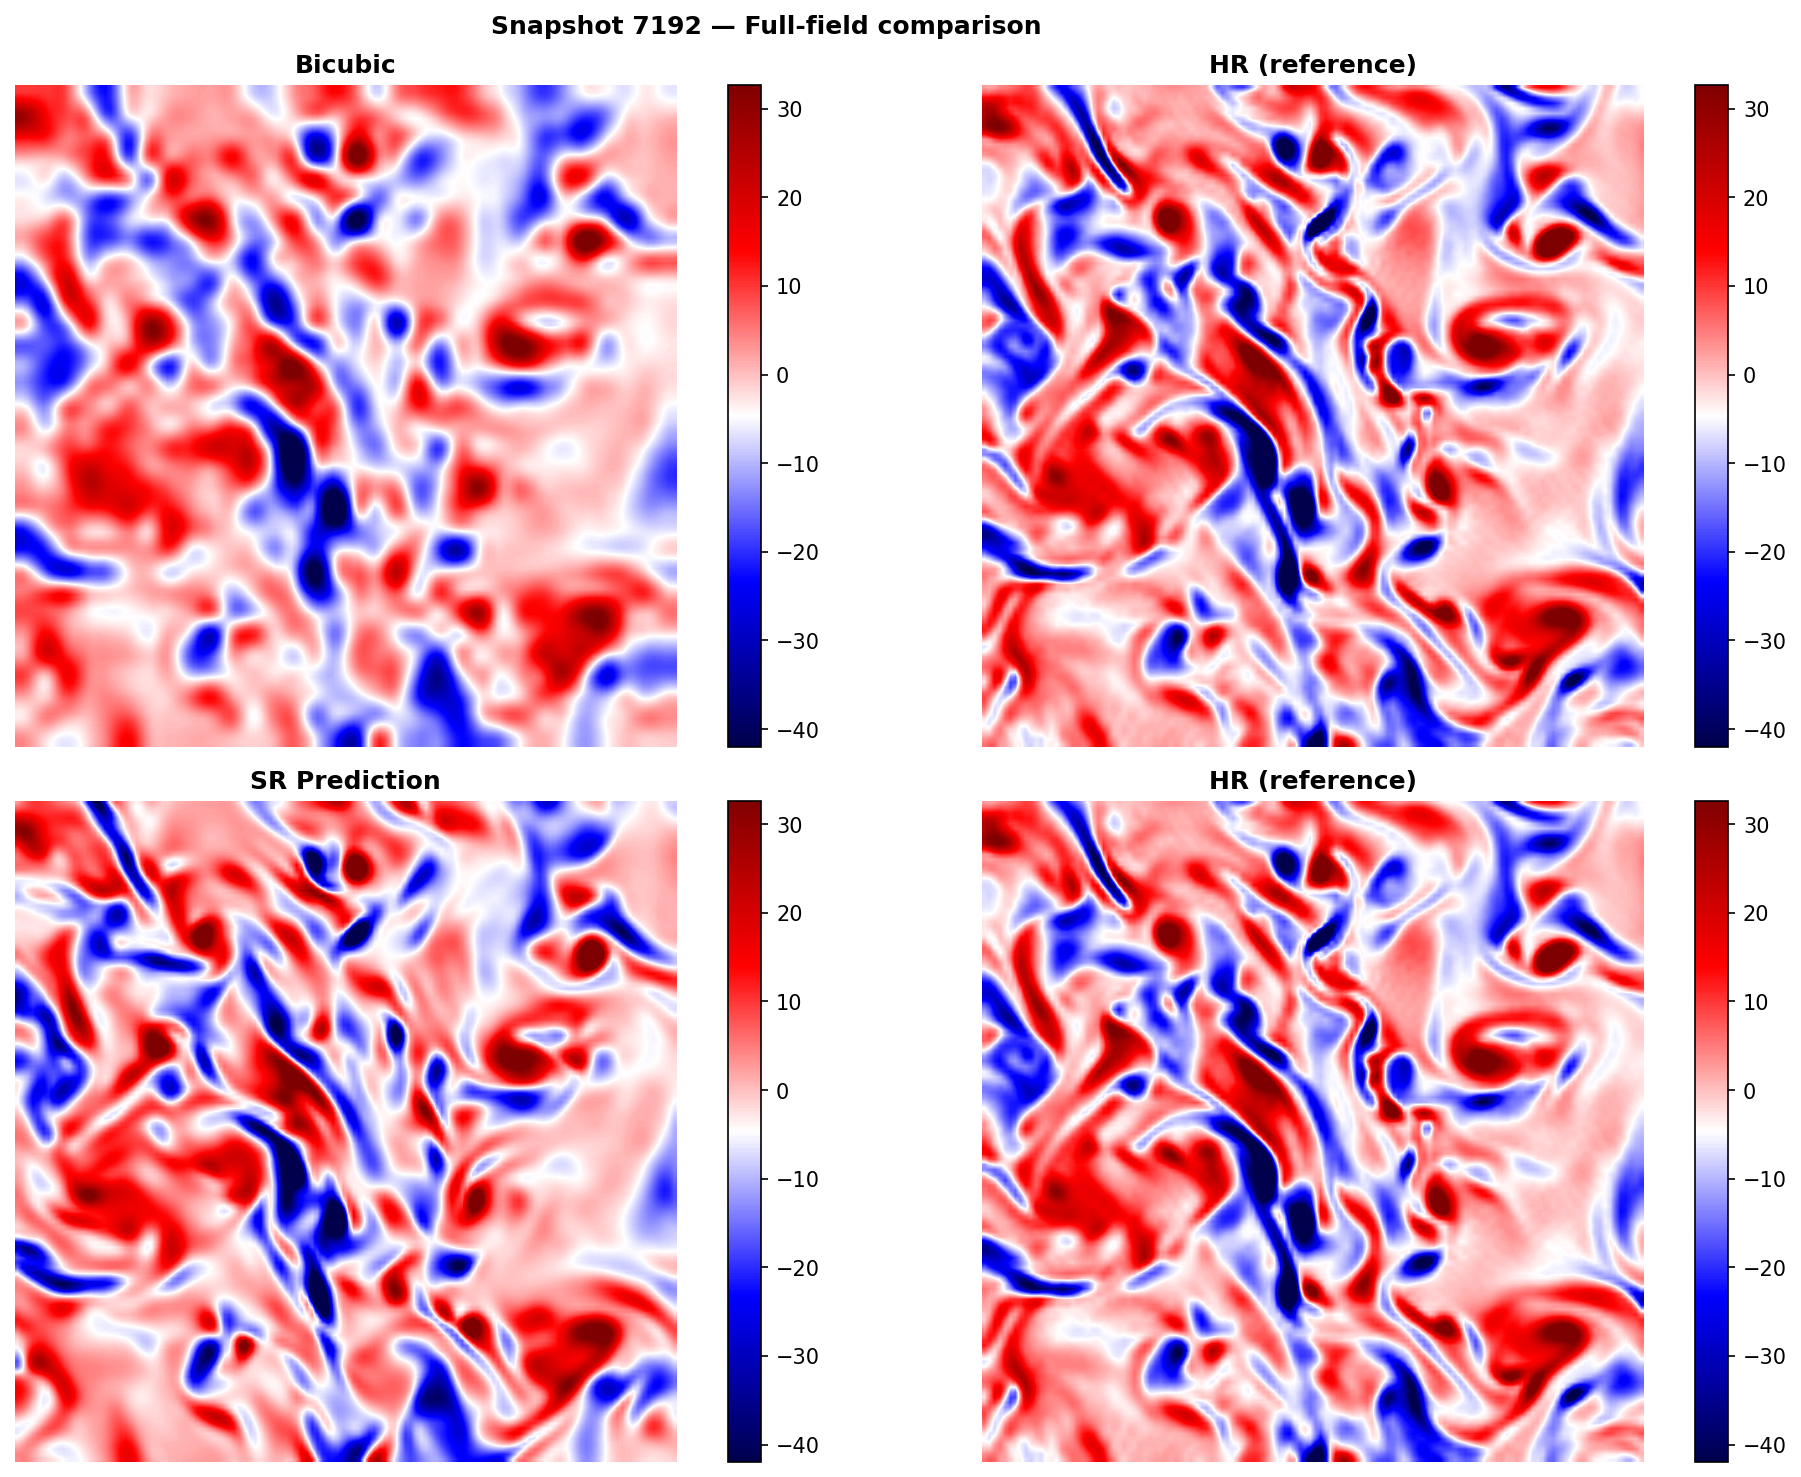

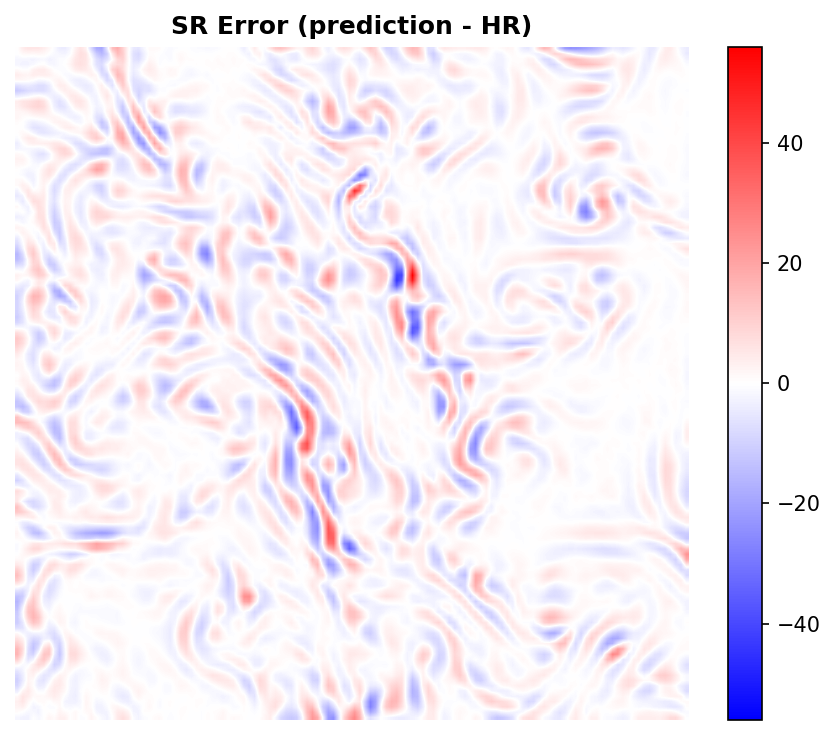

In [33]:
vmin = np.percentile(sample_payload['hr'], 1)
vmax = np.percentile(sample_payload['hr'], 99)

def plot_field(ax, field, title, *, cmap, vmin, vmax, interpolation="bilinear"):
    im = ax.imshow(
        field.T,
        cmap=cmap,
        origin='lower',
        vmin=vmin,
        vmax=vmax,
        interpolation=interpolation,  # smooth visual upsampling
    )
    ax.set_title(title, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)
    return im

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
pairs = [
    ('Bicubic', sample_payload['bicubic'], 'HR (reference)', sample_payload['hr']),
    ('SR Prediction', sample_payload['sr'], 'HR (reference)', sample_payload['hr']),
]

for row, (pred_label, pred_data, ref_label, ref_data) in enumerate(pairs):
    plot_field(
        axes[row, 0],
        pred_data,
        pred_label,
        cmap='seismic',
        vmin=vmin,
        vmax=vmax,
        interpolation="bilinear",  # or "bicubic" / "nearest"
    )
    plot_field(
        axes[row, 1],
        ref_data,
        ref_label,
        cmap='seismic',
        vmin=vmin,
        vmax=vmax,
        interpolation="bilinear",
    )

plt.suptitle(
    f"Snapshot {sample_payload['snapshot']} — Full-field comparison",
    fontweight='bold'
)
plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '01_full_field_comparison.png',
            bbox_inches='tight', dpi=200)
plt.show()

# Error map
fig, ax = plt.subplots(figsize=(6, 5))
err = sample_payload['sr'] - sample_payload['hr']
err_lim = np.max(np.abs(err))
im = ax.imshow(
    err.T,
    cmap='bwr',
    origin='lower',
    vmin=-err_lim,
    vmax=err_lim,
    interpolation="bilinear",  # same smoothing for error plot
)
ax.set_title('SR Error (prediction - HR)', fontweight='bold')
ax.axis('off')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '02_error_map.png',
            bbox_inches='tight', dpi=200)
plt.show()


## Zoomed View & PDFs

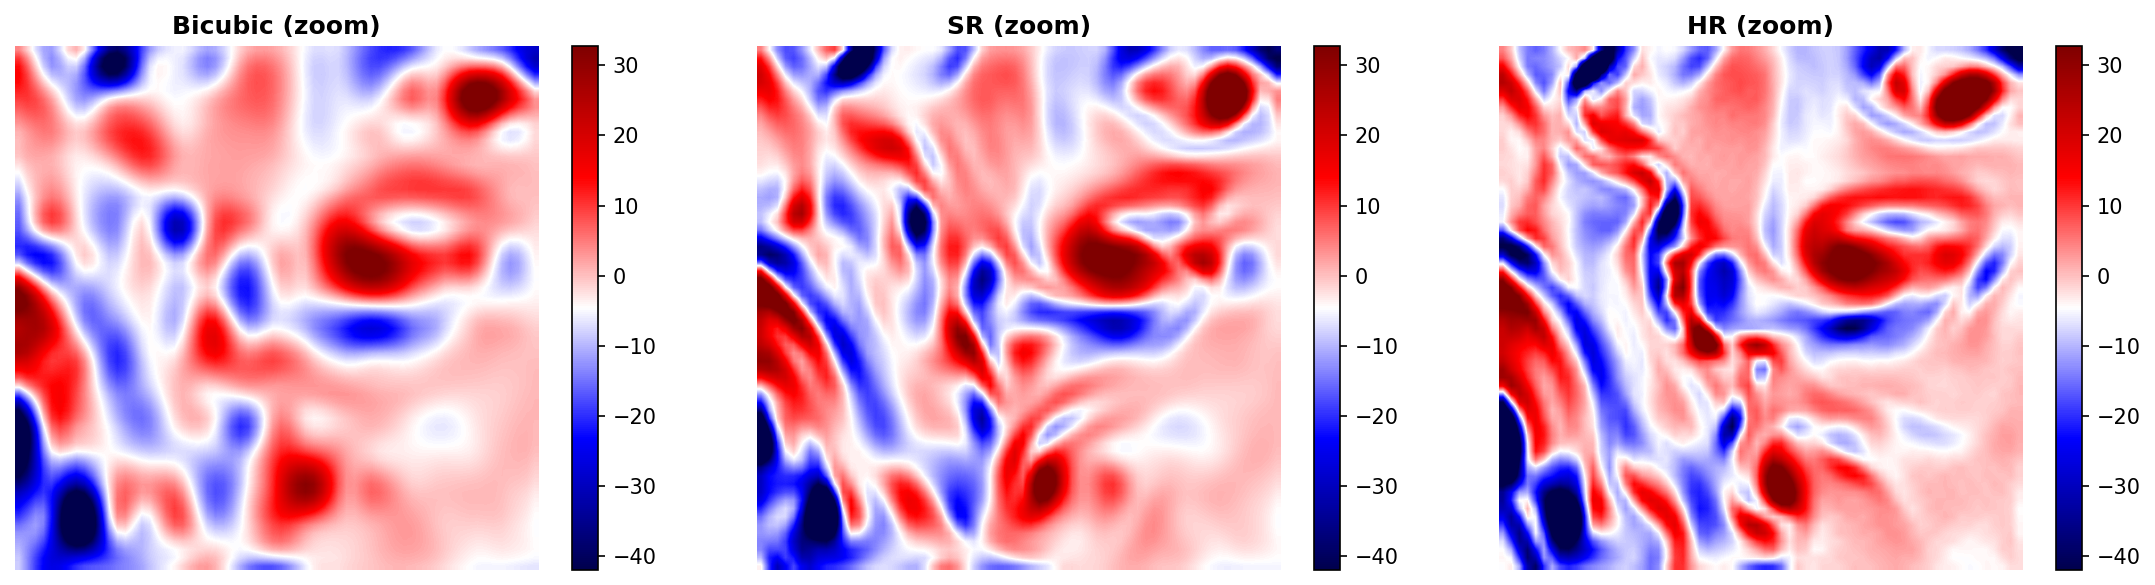

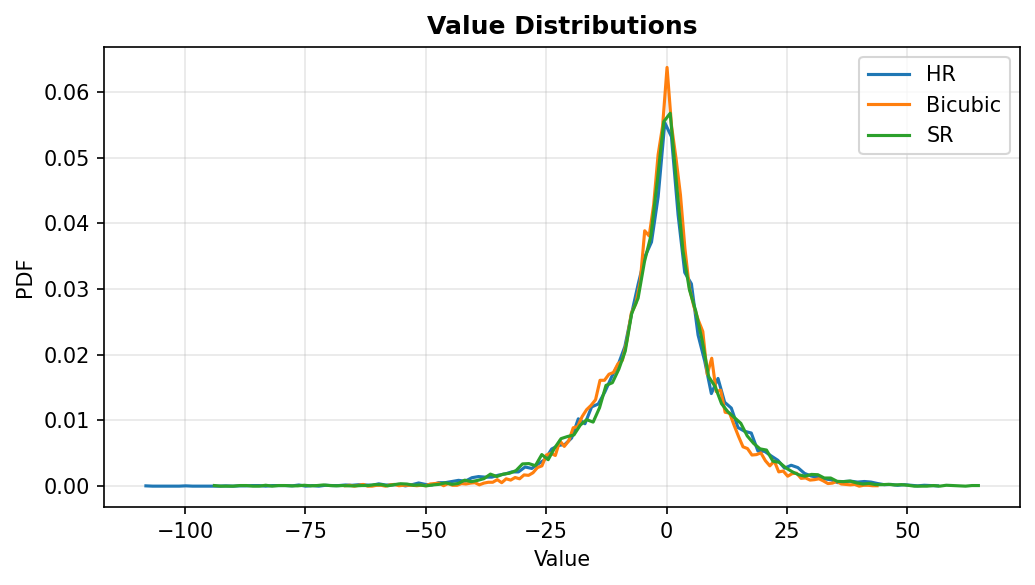

In [34]:

# Random zoom
rng = np.random.default_rng(0)
patch = 64
y0 = rng.integers(0, HR_SIZE - patch)
x0 = rng.integers(0, HR_SIZE - patch)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(
    axes,
    [sample_payload['bicubic'], sample_payload['sr'], sample_payload['hr']],
    ['Bicubic (zoom)', 'SR (zoom)', 'HR (zoom)'],
):
    sub = data[y0:y0+patch, x0:x0+patch]
    im = ax.imshow(sub.T, cmap='seismic', origin='lower', vmin=vmin, vmax=vmax, interpolation="bilinear")
    ax.set_title(title, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '03_zoom_triptych.png', bbox_inches='tight', dpi=200)
plt.show()

# PDFs
fig, ax = plt.subplots(figsize=(7, 4))
for label, data in [('HR', sample_payload['hr']), ('Bicubic', sample_payload['bicubic']), ('SR', sample_payload['sr'])]:
    centers, hist = pdf_from_field(data, bins=120)
    ax.plot(centers, hist, label=label)
ax.set_title('Value Distributions', fontweight='bold')
ax.set_xlabel('Value')
ax.set_ylabel('PDF')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '04_pdf.png', bbox_inches='tight', dpi=200)
plt.show()


## Physics terms diagnostics

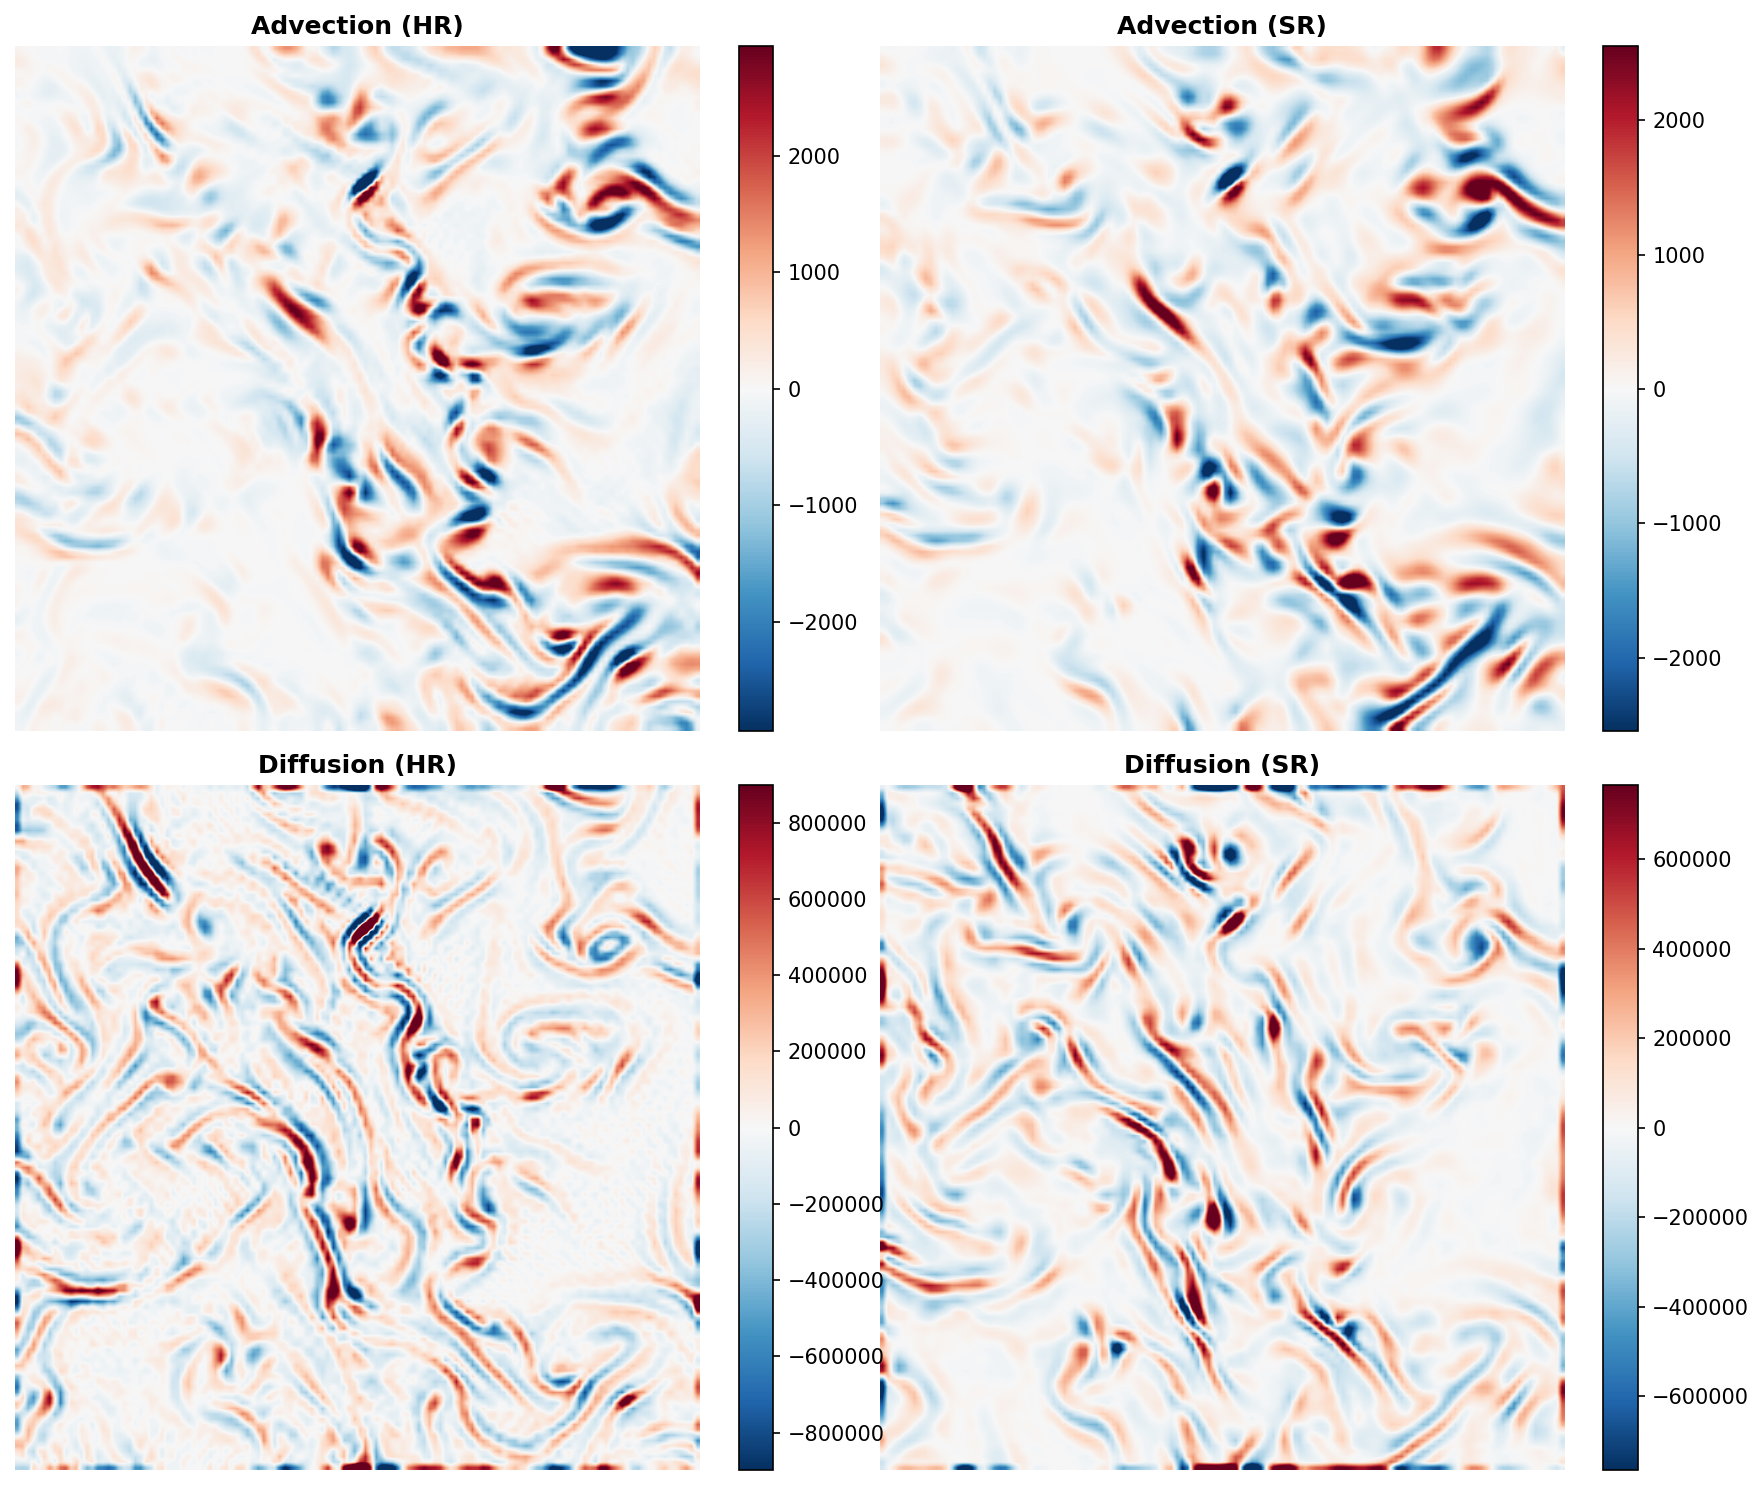

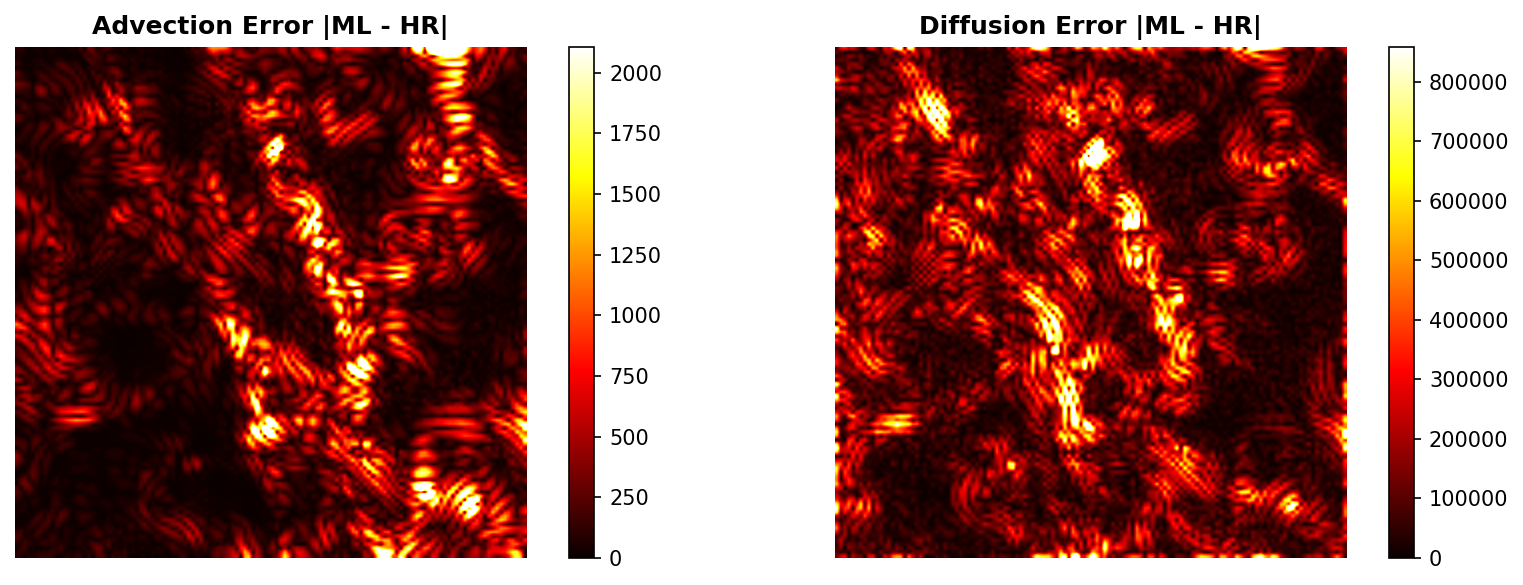

In [36]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
adv_err = sample_payload['adv_sr'] - sample_payload['adv_hr']
diff_err = sample_payload['diff_sr'] - sample_payload['diff_hr']

plots = [
    (sample_payload['adv_hr'], 'Advection (HR)'),
    (sample_payload['adv_sr'], 'Advection (SR)'),
    (sample_payload['diff_hr'], 'Diffusion (HR)'),
    (sample_payload['diff_sr'], 'Diffusion (SR)'),
]
for ax, (data, title) in zip(axes.flat, plots):
    v = np.percentile(np.abs(data), 99)
    im = ax.imshow(data.T, cmap='RdBu_r', origin='lower', vmin=-v, vmax=v, interpolation="bilinear")
    ax.set_title(title, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '05_physics_terms.png', bbox_inches='tight', dpi=200)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title in [
    (axes[0], adv_err, 'Advection Error |ML - HR|'),
    (axes[1], diff_err, 'Diffusion Error |ML - HR|'),
]:
    vmax = np.percentile(np.abs(data), 99)
    im = ax.imshow(np.abs(data).T, cmap='hot', origin='lower', vmin=0, vmax=vmax, interpolation="bilinear")
    ax.set_title(title, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '06_physics_errors.png', bbox_inches='tight', dpi=200)
plt.show()


## Energy spectrum

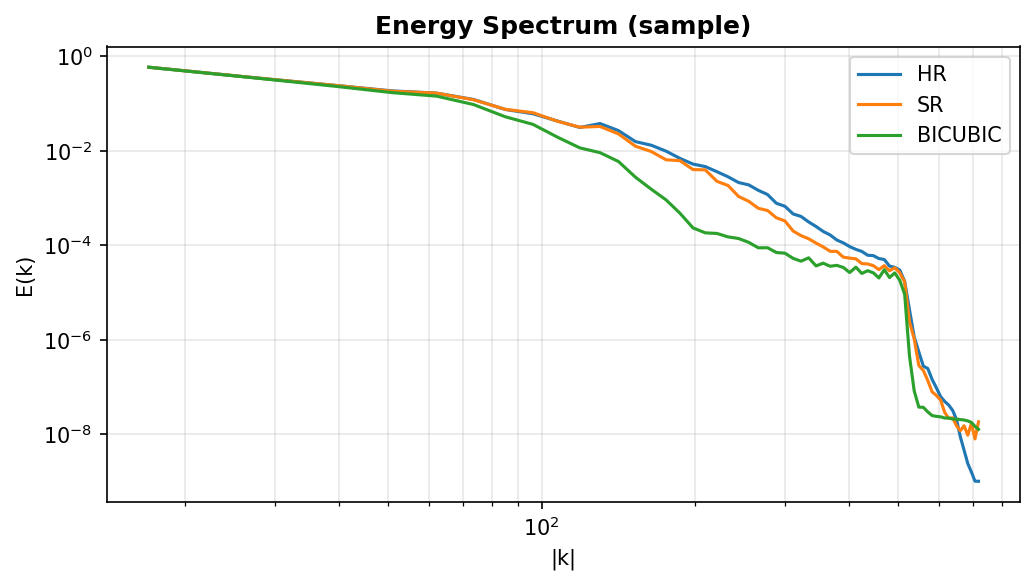

In [37]:

fig, ax = plt.subplots(figsize=(7, 4))
for label, spectra in energy_spectra.items():
    k, e = spectra[0]  # first sample
    ax.loglog(k[1:], e[1:], label=label.upper())
ax.set_xlabel('|k|')
ax.set_ylabel('E(k)')
ax.set_title('Energy Spectrum (sample)', fontweight='bold')
ax.legend()
ax.grid(which='both', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_EVAL_DIR / '07_energy_spectrum.png', bbox_inches='tight', dpi=200)
plt.show()


## Summary

In [26]:
print('=' * 70)
print('POSTPROCESSING SUMMARY')
print('=' * 70)
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Figures:   {FIGURES_EVAL_DIR}")
print(f"Per-snapshot metrics: {PER_SNAPSHOT_PATH}")
print(f"Aggregate metrics:   {METRICS_PATH}")

if evaluation_metrics_summary:
    sr_psnr = evaluation_metrics_summary['pixel_metrics']['sr']['psnr']['mean']
    bi_psnr = evaluation_metrics_summary['pixel_metrics']['bicubic']['psnr']['mean']
    sr_adv = evaluation_metrics_summary['physics_metrics']['advection_mae']['sr']['mean']
    bi_adv = evaluation_metrics_summary['physics_metrics']['advection_mae']['bicubic']['mean']
    print(f"Mean PSNR (SR):      {sr_psnr:.2f} dB")
    print(f"Mean PSNR (bicubic): {bi_psnr:.2f} dB")
    print(f"Advection MAE (SR):      {sr_adv:.4f}")
    print(f"Advection MAE (bicubic): {bi_adv:.4f}")
else:
    print("No evaluation metrics computed.")
print('=' * 70)

POSTPROCESSING SUMMARY
Checkpoint: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics/checkpoints/last_model.pth
Figures:   /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics/plots/evaluation
Per-snapshot metrics: /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics/metrics/per_snapshot_metrics.csv
Aggregate metrics:   /workspaces/jhtdb-ml/work/SR/sr_unet_meteo_isotropic_128_withPhysics/metrics/evaluation_metrics.json
Mean PSNR (SR):      22.93 dB
Mean PSNR (bicubic): 22.97 dB
Advection MAE (SR):      524.9184
Advection MAE (bicubic): 483.0602
